📁 Directorio de trabajo actual: c:\Users\Jesus\proyecto-eda

--- INFORME DE PLATAFORMA Y CONFIGURACIÓN ---
Sistema Operativo: Windows 10
Versión de Python: 3.14.7
Procesador: Intel64 Family 6 Model 60 Stepping 3, GenuineIntel
Semilla (Seed): 42

Procesando dataset: 1K...
Procesando dataset: 10K...
Procesando dataset: 100K...
Procesando dataset: 1M...
Procesando dataset: 10M...

📊 RESULTADOS OBTENIDOS EN TU MÁQUINA (ESCALA REAL):


,Dataset,Elementos (N),Repeticiones,Tiempo Prom. (ms),Desv. Estándar (ms),Memoria Pico (MB)
0,1K,1000,100,5.46,4.96,0.09
1,10K,10000,100,42.28,12.82,1.17
2,100K,100000,100,472.65,62.90,11.44
3,1M,1000000,20,4563.73,275.90,102.36
4,10M,10000000,5,42189.41,4982.96,927.60


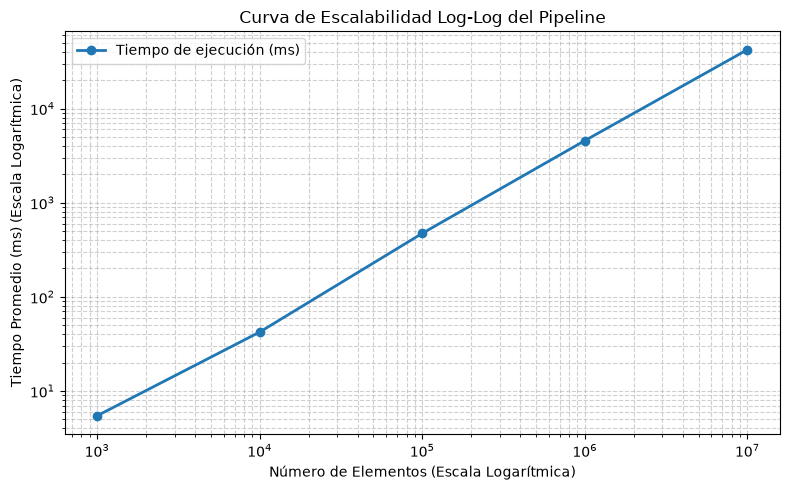

In [15]:
import gc
import os
import platform
import random
import statistics
import time
import tracemalloc
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# --- AJUSTE AUTOMÁTICO DE RUTA (Resuelve el error de archivo no encontrado) ---
if os.path.basename(os.getcwd()) == 'notebooks':
  os.chdir('..')
print(f'📁 Directorio de trabajo actual: {os.getcwd()}\n')

# 1. Configuración de Semilla y Plataforma
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print('========================================================')
print('--- INFORME DE PLATAFORMA Y CONFIGURACIÓN ---')
print(f'Sistema Operativo: {platform.system()} {platform.release()}')
print(f'Versión de Python: {platform.python_version()}')
print(f'Procesador: {platform.processor()}')
print(f'Semilla (Seed): {SEED}')
print('========================================================\n')

# 2. Medición sobre datasets de 1K a 10M (Evaluando el total de elementos N)
DATASET_SIZES = ['1K', '10K', '100K', '1M', '10M']
results_summary = []

for size_str in DATASET_SIZES:
  file_path = f'data/ecommerce_{size_str}.parquet'
  print(f'Procesando dataset: {size_str}...')

  try:
    df = pd.read_parquet(file_path)
  except Exception as e:
    print(f'⚠️ No se pudo cargar {file_path}: {e}')
    continue

  # --- CALENTAMIENTO (Warm-up) ---
  # Ejecución previa para estabilizar cachés y el intérprete antes de medir.
  sample_data = df['event_id'].tolist()
  _ = set(sample_data)

  # Ajuste de repeticiones según escala
  repetitions = 5 if size_str == '10M' else (20 if size_str == '1M' else 100)
  execution_times = []
  peak_memories = []

  # --- DESACTIVACIÓN TEMPORAL DEL GARBAGE COLLECTOR ---
  # Aisla la métrica de tiempo evitando interrupciones del recolector de basura.
  gc.disable()
  try:
    for rep in range(repetitions):
      tracemalloc.start()
      start_time = time.perf_counter()

      # --- MEDICIÓN REAL SOBRE EL TOTAL DE ELEMENTOS DEL DATASET (N) ---
      sample_data = df['event_id'].tolist()
      _ = set(sample_data)

      end_time = time.perf_counter()
      _, peak_mem = tracemalloc.get_traced_memory()
      tracemalloc.stop()

      execution_times.append((end_time - start_time) * 1000)  # ms
      peak_memories.append(peak_mem / (1024 * 1024))  # MB
  finally:
    # Se asegura de reactivar el recolector de basura pase lo que pase
    gc.enable()

  mean_time = statistics.mean(execution_times)
  stdev_time = (
      statistics.stdev(execution_times) if len(execution_times) > 1 else 0.0
  )
  mean_mem = statistics.mean(peak_memories)

  results_summary.append({
      'Dataset': size_str,
      'Elementos (N)': len(df),
      'Repeticiones': repetitions,
      'Tiempo Prom. (ms)': round(mean_time, 2),
      'Desv. Estándar (ms)': round(stdev_time, 2),
      'Memoria Pico (MB)': round(mean_mem, 2),
  })

df_results = pd.DataFrame(results_summary)
print('\n📊 RESULTADOS OBTENIDOS EN TU MÁQUINA (ESCALA REAL):')
display(df_results)

# 3. Generación del gráfico Log-Log de Escalabilidad (Matplotlib)
if not df_results.empty:
  plt.figure(figsize=(8, 5))
  plt.plot(
      df_results['Elementos (N)'],
      df_results['Tiempo Prom. (ms)'],
      marker='o',
      linewidth=2,
      color='#1f77b4',
      label='Tiempo de ejecución (ms)',
  )
  plt.xscale('log')
  plt.yscale('log')
  plt.xlabel('Número de Elementos (Escala Logarítmica)')
  plt.ylabel('Tiempo Promedio (ms) (Escala Logarítmica)')
  plt.title('Curva de Escalabilidad Log-Log del Pipeline')
  plt.grid(True, which='both', linestyle='--', alpha=0.6)
  plt.legend()
  plt.tight_layout()
  plt.show()